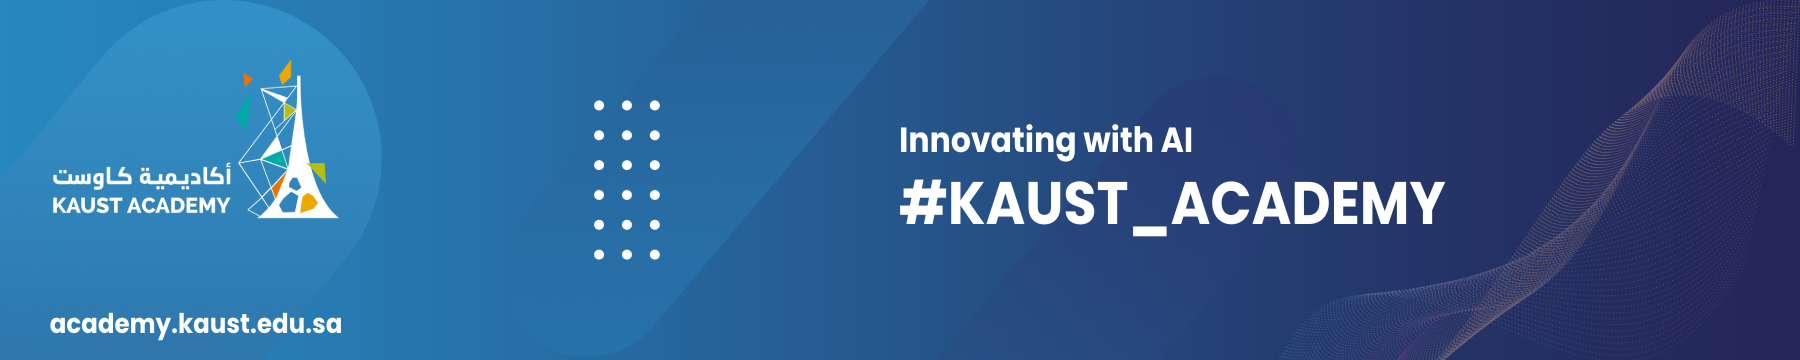

## Setup

In [1]:
# Keep Kaggle's preinstalled PyTorch build.

%pip install -q \
    "flappy-bird-gymnasium==0.4.0" \
    "stable-baselines3>=2.5,<3" \
    imageio \
    matplotlib \
    pillow \
    tqdm \
    rich

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 36.2 MB/s eta 0:00:0000:01:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 9.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


# Content

In this lab, we build a **Dueling Double DQN** agent from scratch in PyTorch and train it to solve the Flappy Bird environment.

For the environment, we use `flappy_bird_gymnasium`. You can read more about it [here](https://github.com/markub3327/flappy-bird-gymnasium).

> This implementation combines several value-based reinforcement learning improvements:
>
> - **Dueling DQN** separates the estimation of the state value \(V(s)\) from the action advantage \(A(s,a)\).
> - **Double DQN** reduces Q-value overestimation by using the online network to select the next action and the target network to evaluate it.
> - **Prioritized Experience Replay** samples important transitions more frequently based on their TD error.
> - **Biased epsilon-greedy exploration** makes exploratory flaps rare, since randomly flapping on half of all frames is destructive in Flappy Bird.
>
> The agent is considered to have solved the environment when it reaches a true pipe score of **1000** during deterministic evaluation.

In [2]:
import json
import os
import random
import shutil
import time
from pathlib import Path

os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")

import gymnasium as gym
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image as IPyImage
from IPython.display import display
from PIL import Image as PILImage
from PIL import ImageDraw
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import SubprocVecEnv
from tqdm.auto import tqdm

import flappy_bird_gymnasium

SEED = 42
TARGET_SCORE = 1000
PIPE_GAP = 100

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

CPU_COUNT = os.cpu_count() or 1

# Kaggle with 4 logical CPUs -> 3 environments.
# A local 12600K-class CPU -> up to 8 environments.
if CPU_COUNT >= 10:
    N_ENVS = 8
elif CPU_COUNT >= 6:
    N_ENVS = CPU_COUNT - 2
elif CPU_COUNT >= 4:
    N_ENVS = CPU_COUNT - 1
else:
    N_ENVS = max(1, CPU_COUNT)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Avoid PyTorch and the environment processes competing
# through separate CPU thread pools.
torch.set_num_threads(1)

WORK_DIR = (
    Path("/kaggle/working")
    if Path("/kaggle/working").exists()
    else Path.cwd()
)

MODEL_DIR = WORK_DIR / "flappy_ddqn"
CHECKPOINT_DIR = MODEL_DIR / "checkpoints"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_model.pt"
FINAL_MODEL_PATH = MODEL_DIR / "final_model.pt"
EXPORT_MODEL_PATH = (
    WORK_DIR / "flappy_ddqn_score_1000.pt"
)
GIF_PATH = (
    WORK_DIR
    / "flappy_ddqn_first_10_scores.gif"
)

print(f"PyTorch: {torch.__version__}")
print(f"Logical CPUs available: {CPU_COUNT}")
print(f"Parallel environments: {N_ENVS}")
print(f"Training device: {DEVICE}")
print(f"Target score: {TARGET_SCORE}")
print(f"Output directory: {MODEL_DIR}")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


PyTorch: 2.10.0+cpu
Logical CPUs available: 4
Parallel environments: 3
Training device: cpu
Target score: 1000
Output directory: /kaggle/working/flappy_ddqn


/usr/local/lib/python3.12/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## Environment and training reward

In [3]:
# Training-only reward shaping.
# Evaluation will use the original environment reward.

SURVIVAL_REWARD = 0.05
PIPE_REWARD = 5.0
DEATH_PENALTY = -5.0
TOP_PENALTY = -1.0


class FlappyRewardWrapper(gym.Wrapper):
    """Prioritise passing pipes over passive survival."""

    def __init__(self, env):
        super().__init__(env)
        self.previous_score = 0

    def reset(self, **kwargs):
        observation, info = self.env.reset(**kwargs)

        self.previous_score = int(
            info.get("score", 0)
        )

        return observation, info

    def step(self, action):
        (
            observation,
            original_reward,
            terminated,
            truncated,
            info,
        ) = self.env.step(action)

        info = dict(info)

        current_score = int(
            info.get(
                "score",
                self.previous_score,
            )
        )

        pipes_passed = max(
            0,
            current_score - self.previous_score,
        )

        shaped_reward = (
            SURVIVAL_REWARD
            + PIPE_REWARD * pipes_passed
        )

        if terminated:
            shaped_reward += DEATH_PENALTY
        elif float(original_reward) < 0:
            shaped_reward += TOP_PENALTY

        self.previous_score = current_score

        info["original_reward"] = float(
            original_reward
        )
        info["shaped_reward"] = float(
            shaped_reward
        )

        return (
            observation,
            float(shaped_reward),
            terminated,
            truncated,
            info,
        )


def make_flappy_env(
    rank,
    seed=SEED,
    score_limit=TARGET_SCORE,
):
    """Create one seeded training environment."""

    def _init():
        import os

        os.environ[
            "SDL_VIDEODRIVER"
        ] = "dummy"

        os.environ[
            "PYGAME_HIDE_SUPPORT_PROMPT"
        ] = "1"

        import gymnasium as gym
        import flappy_bird_gymnasium

        env = gym.make(
            "FlappyBird-v0",
            render_mode=None,
            use_lidar=False,
            normalize_obs=True,
            pipe_gap=PIPE_GAP,
            score_limit=score_limit,
            audio_on=False,
        )

        env = FlappyRewardWrapper(env)

        env = Monitor(
            env,
            info_keywords=("score",),
        )

        env.reset(seed=seed + rank)
        env.action_space.seed(seed + rank)

        return env

    return _init


def make_evaluation_env(
    target_score=TARGET_SCORE,
    render_mode=None,
):
    """Create an unmodified environment for honest evaluation."""

    return gym.make(
        "FlappyBird-v0",
        render_mode=render_mode,
        use_lidar=False,
        normalize_obs=True,
        pipe_gap=PIPE_GAP,
        score_limit=target_score,
        audio_on=False,
    )

## Cell 4 — Prioritised replay and dueling network

In [4]:
class PrioritizedReplayBuffer:
    """Proportional PER implemented with a sum tree."""

    def __init__(
        self,
        capacity,
        state_dim,
        alpha=0.3,
        priority_epsilon=1e-5,
    ):
        self.capacity = int(capacity)
        self.state_dim = int(state_dim)
        self.alpha = float(alpha)
        self.priority_epsilon = float(priority_epsilon)

        tree_capacity = 1
        while tree_capacity < self.capacity:
            tree_capacity *= 2

        self.tree_capacity = tree_capacity

        self.priority_tree = np.zeros(
            2 * tree_capacity,
            dtype=np.float32,
        )

        self.states = np.empty(
            (self.capacity, self.state_dim),
            dtype=np.float32,
        )
        self.next_states = np.empty_like(self.states)
        self.actions = np.empty(
            self.capacity,
            dtype=np.int64,
        )
        self.rewards = np.empty(
            self.capacity,
            dtype=np.float32,
        )
        self.dones = np.empty(
            self.capacity,
            dtype=np.float32,
        )

        self.position = 0
        self.size = 0
        self.max_priority = 1.0

    def __len__(self):
        return self.size

    def _set_priority(self, data_index, priority):
        tree_index = self.tree_capacity + int(data_index)

        change = (
            float(priority)
            - float(self.priority_tree[tree_index])
        )

        while tree_index >= 1:
            self.priority_tree[tree_index] += change
            tree_index //= 2

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        done,
    ):
        index = self.position

        self.states[index] = np.asarray(
            state,
            dtype=np.float32,
        )
        self.actions[index] = int(action)
        self.rewards[index] = float(reward)
        self.next_states[index] = np.asarray(
            next_state,
            dtype=np.float32,
        )
        self.dones[index] = float(done)

        self._set_priority(
            index,
            self.max_priority,
        )

        self.position = (
            self.position + 1
        ) % self.capacity

        self.size = min(
            self.size + 1,
            self.capacity,
        )

    def add_batch(
        self,
        states,
        actions,
        rewards,
        next_states,
        dones,
    ):
        for index in range(len(actions)):
            self.add(
                states[index],
                actions[index],
                rewards[index],
                next_states[index],
                dones[index],
            )

    def _find_prefix_sum_index(self, mass):
        tree_index = 1

        while tree_index < self.tree_capacity:
            left = 2 * tree_index
            left_priority = self.priority_tree[left]

            if mass < left_priority:
                tree_index = left
            else:
                mass -= left_priority
                tree_index = left + 1

        data_index = tree_index - self.tree_capacity

        return min(
            data_index,
            self.size - 1,
        )

    def sample(
        self,
        batch_size,
        beta,
        device,
    ):
        if self.size < batch_size:
            raise ValueError(
                "Replay buffer does not contain enough samples."
            )

        total_priority = float(
            self.priority_tree[1]
        )

        if total_priority <= 0:
            raise RuntimeError(
                "Replay priorities must be positive."
            )

        segment = total_priority / batch_size

        indices = np.empty(
            batch_size,
            dtype=np.int64,
        )
        priorities = np.empty(
            batch_size,
            dtype=np.float32,
        )

        for sample_index in range(batch_size):
            low = segment * sample_index
            high = segment * (sample_index + 1)

            mass = np.random.uniform(low, high)

            data_index = (
                self._find_prefix_sum_index(mass)
            )

            indices[sample_index] = data_index
            priorities[sample_index] = (
                self.priority_tree[
                    self.tree_capacity + data_index
                ]
            )

        probabilities = priorities / total_priority
        probabilities = np.maximum(
            probabilities,
            1e-12,
        )

        weights = (
            self.size * probabilities
        ) ** (-float(beta))

        weights /= weights.max() + 1e-8

        return {
            "states": torch.as_tensor(
                self.states[indices],
                device=device,
            ),
            "actions": torch.as_tensor(
                self.actions[indices],
                device=device,
            ),
            "rewards": torch.as_tensor(
                self.rewards[indices],
                device=device,
            ),
            "next_states": torch.as_tensor(
                self.next_states[indices],
                device=device,
            ),
            "dones": torch.as_tensor(
                self.dones[indices],
                device=device,
            ),
            "weights": torch.as_tensor(
                weights,
                dtype=torch.float32,
                device=device,
            ),
            "indices": indices,
        }

    def update_priorities(
        self,
        indices,
        td_errors,
    ):
        priorities = (
            np.abs(
                np.asarray(
                    td_errors,
                    dtype=np.float32,
                )
            )
            + self.priority_epsilon
        ) ** self.alpha

        for data_index, priority in zip(
            indices,
            priorities,
        ):
            self._set_priority(
                int(data_index),
                float(priority),
            )

        self.max_priority = max(
            self.max_priority,
            float(priorities.max()),
        )


class DuelingQNetwork(nn.Module):
    """Shared features with value and advantage streams."""

    def __init__(
        self,
        state_dim,
        action_dim,
        hidden_dim=192,
    ):
        super().__init__()

        self.state_dim = int(state_dim)
        self.action_dim = int(action_dim)
        self.hidden_dim = int(hidden_dim)

        self.features = nn.Sequential(
            nn.Linear(
                self.state_dim,
                self.hidden_dim,
            ),
            nn.ReLU(),
            nn.Linear(
                self.hidden_dim,
                self.hidden_dim,
            ),
            nn.ReLU(),
        )

        self.value_stream = nn.Sequential(
            nn.Linear(
                self.hidden_dim,
                128,
            ),
            nn.ReLU(),
            nn.Linear(128, 1),
        )

        self.advantage_stream = nn.Sequential(
            nn.Linear(
                self.hidden_dim,
                128,
            ),
            nn.ReLU(),
            nn.Linear(
                128,
                self.action_dim,
            ),
        )

    def forward(self, states):
        features = self.features(states)

        values = self.value_stream(features)
        advantages = self.advantage_stream(features)

        return (
            values
            + advantages
            - advantages.mean(
                dim=1,
                keepdim=True,
            )
        )

    @torch.no_grad()
    def choose_actions(
        self,
        states,
        epsilon=0.0,
        exploration_flap_probability=0.08,
    ):
        """
        Epsilon-greedy exploration with biased random actions.

        A random exploratory action is not chosen 50/50.
        Flap is an impulse and should be relatively rare.
        """

        state_tensor = torch.as_tensor(
            np.asarray(
                states,
                dtype=np.float32,
            ),
            device=next(
                self.parameters()
            ).device,
        )

        q_values = self(state_tensor)

        greedy_actions = (
            q_values
            .argmax(dim=1)
            .cpu()
            .numpy()
        )

        if epsilon <= 0:
            return greedy_actions.astype(
                np.int64
            )

        batch_size = len(greedy_actions)

        explore_mask = (
            np.random.random(batch_size)
            < epsilon
        )

        exploratory_actions = (
            np.random.random(batch_size)
            < exploration_flap_probability
        ).astype(np.int64)

        return np.where(
            explore_mask,
            exploratory_actions,
            greedy_actions,
        ).astype(np.int64)

## Cell 5 — DDQN optimisation, evaluation and saving

In [5]:
def linear_schedule(
    step,
    start_value,
    end_value,
    duration,
):
    fraction = min(
        max(
            step / max(duration, 1),
            0.0,
        ),
        1.0,
    )

    return (
        start_value
        + fraction
        * (end_value - start_value)
    )


def optimize_double_dqn(
    online_network,
    target_network,
    optimizer,
    replay_buffer,
    batch_size,
    gamma,
    beta,
):
    """One Dueling Double-DQN update."""

    batch = replay_buffer.sample(
        batch_size=batch_size,
        beta=beta,
        device=DEVICE,
    )

    q_values = online_network(
        batch["states"]
    ).gather(
        1,
        batch["actions"].unsqueeze(1),
    ).squeeze(1)

    with torch.no_grad():
        # Online network chooses the action.
        next_actions = online_network(
            batch["next_states"]
        ).argmax(
            dim=1,
            keepdim=True,
        )

        # Target network evaluates that action.
        next_q_values = target_network(
            batch["next_states"]
        ).gather(
            1,
            next_actions,
        ).squeeze(1)

        targets = (
            batch["rewards"]
            + gamma
            * (1.0 - batch["dones"])
            * next_q_values
        )

    td_errors = targets - q_values

    per_sample_loss = (
        F.smooth_l1_loss(
            q_values,
            targets,
            reduction="none",
        )
    )

    loss = (
        batch["weights"]
        * per_sample_loss
    ).mean()

    optimizer.zero_grad(
        set_to_none=True
    )

    loss.backward()

    nn.utils.clip_grad_norm_(
        online_network.parameters(),
        max_norm=10.0,
    )

    optimizer.step()

    replay_buffer.update_priorities(
        batch["indices"],
        td_errors
        .detach()
        .cpu()
        .numpy(),
    )

    return {
        "loss": float(loss.item()),
        "mean_q": float(
            q_values
            .detach()
            .mean()
            .item()
        ),
        "mean_abs_td_error": float(
            td_errors
            .detach()
            .abs()
            .mean()
            .item()
        ),
    }


@torch.no_grad()
def evaluate_dqn(
    network,
    target_score=TARGET_SCORE,
    seeds=(2026, 2027, 2028),
    max_steps=60_000,
):
    """Greedy evaluation using the original reward."""

    was_training = network.training
    network.eval()

    results = []

    for seed in seeds:
        env = make_evaluation_env(
            target_score=target_score,
            render_mode=None,
        )

        observation, info = env.reset(
            seed=int(seed)
        )

        total_reward = 0.0
        score = int(
            info.get("score", 0)
        )

        terminated = False
        truncated = False
        safety_limit_reached = False
        steps = 0

        for steps in range(
            1,
            max_steps + 1,
        ):
            action = int(
                network.choose_actions(
                    np.expand_dims(
                        observation,
                        axis=0,
                    ),
                    epsilon=0.0,
                )[0]
            )

            (
                observation,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            total_reward += float(reward)

            score = int(
                info.get("score", score)
            )

            if terminated or truncated:
                break
        else:
            safety_limit_reached = True

        env.close()

        results.append(
            {
                "seed": int(seed),
                "score": int(score),
                "reward": float(
                    total_reward
                ),
                "steps": int(steps),
                "target_reached": (
                    score >= target_score
                ),
                "terminated": bool(
                    terminated
                ),
                "truncated": bool(
                    truncated
                ),
                "safety_limit_reached": bool(
                    safety_limit_reached
                ),
            }
        )

    scores = [
        result["score"]
        for result in results
    ]

    summary = {
        "episodes": results,
        "scores": scores,
        "mean_score": float(
            np.mean(scores)
        ),
        "minimum_score": int(
            np.min(scores)
        ),
        "maximum_score": int(
            np.max(scores)
        ),
        "solved": bool(
            all(
                score >= target_score
                for score in scores
            )
        ),
    }

    if was_training:
        network.train()

    return summary


def save_dqn_checkpoint(
    path,
    online_network,
    target_network,
    optimizer,
    global_step,
    config,
    evaluation=None,
):
    checkpoint = {
        "algorithm": (
            "Dueling Double DQN with "
            "Prioritized Experience Replay"
        ),
        "online_state_dict": (
            online_network.state_dict()
        ),
        "target_state_dict": (
            target_network.state_dict()
        ),
        "optimizer_state_dict": (
            optimizer.state_dict()
        ),
        "global_step": int(global_step),
        "config": dict(config),
        "evaluation": evaluation,
    }

    torch.save(
        checkpoint,
        Path(path),
    )


def load_dqn_checkpoint(
    path,
    device=DEVICE,
    load_optimizer=False,
):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Model file not found: {path}"
        )

    try:
        checkpoint = torch.load(
            path,
            map_location=device,
            weights_only=False,
        )
    except TypeError:
        checkpoint = torch.load(
            path,
            map_location=device,
        )

    config = checkpoint["config"]

    network = DuelingQNetwork(
        state_dim=int(
            config["state_dim"]
        ),
        action_dim=int(
            config["action_dim"]
        ),
        hidden_dim=int(
            config["hidden_dim"]
        ),
    ).to(device)

    network.load_state_dict(
        checkpoint["online_state_dict"]
    )

    network.eval()

    if not load_optimizer:
        return network, checkpoint

    target_network = DuelingQNetwork(
        state_dim=int(
            config["state_dim"]
        ),
        action_dim=int(
            config["action_dim"]
        ),
        hidden_dim=int(
            config["hidden_dim"]
        ),
    ).to(device)

    target_network.load_state_dict(
        checkpoint["target_state_dict"]
    )

    optimizer = torch.optim.Adam(
        network.parameters(),
        lr=float(
            config["learning_rate"]
        ),
    )

    optimizer.load_state_dict(
        checkpoint[
            "optimizer_state_dict"
        ]
    )

    return (
        network,
        target_network,
        optimizer,
        checkpoint,
    )

## Cell 6 — Model and training configuration

In [6]:
TOTAL_TIMESTEPS = 3_000_000
EVAL_INTERVAL = 250_000
CHECKPOINT_INTERVAL = 250_000

BUFFER_SIZE = 500_000
LEARNING_STARTS = 20_000
BATCH_SIZE = 256

GAMMA = 0.99
LEARNING_RATE = 1e-4
HIDDEN_DIM = 192

# One update per vector step.
# With three environments, this is one update per three transitions.
TRAIN_EVERY_VECTOR_STEPS = 1
GRADIENT_STEPS = 1

TARGET_UPDATE_INTERVAL = 10_000

EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY_STEPS = 400_000

# During an exploratory decision, flap only 8% of the time.
EXPLORATION_FLAP_PROBABILITY = 0.08

# Weaken PER so early death transitions do not dominate.
PER_ALPHA = 0.3
PER_BETA_START = 0.4
PER_BETA_END = 1.0
PER_BETA_STEPS = TOTAL_TIMESTEPS

EVALUATION_SEEDS = (
    2026,
    2027,
    2028,
)

try:
    if "train_env" in globals():
        train_env.close()
except Exception:
    pass

train_env = SubprocVecEnv(
    [
        make_flappy_env(rank=index)
        for index in range(N_ENVS)
    ]
)

print("Testing parallel environments...")

smoke_start = time.perf_counter()
smoke_observations = train_env.reset()

SMOKE_STEPS = 200

for _ in range(SMOKE_STEPS):
    # Smoke test uses the same biased random-action distribution
    # as the corrected exploration policy.
    smoke_actions = (
        np.random.random(N_ENVS)
        < EXPLORATION_FLAP_PROBABILITY
    ).astype(np.int64)

    (
        smoke_observations,
        smoke_rewards,
        smoke_dones,
        smoke_infos,
    ) = train_env.step(smoke_actions)

smoke_seconds = (
    time.perf_counter() - smoke_start
)

smoke_transitions = (
    SMOKE_STEPS * N_ENVS
)

print(
    f"Parallel smoke test passed: "
    f"{smoke_transitions:,} transitions in "
    f"{smoke_seconds:.2f}s "
    f"({smoke_transitions / smoke_seconds:.0f} FPS)"
)

observations = train_env.reset()

STATE_DIM = int(
    train_env.observation_space.shape[0]
)

ACTION_DIM = int(
    train_env.action_space.n
)

online_network = DuelingQNetwork(
    state_dim=STATE_DIM,
    action_dim=ACTION_DIM,
    hidden_dim=HIDDEN_DIM,
).to(DEVICE)

target_network = DuelingQNetwork(
    state_dim=STATE_DIM,
    action_dim=ACTION_DIM,
    hidden_dim=HIDDEN_DIM,
).to(DEVICE)

target_network.load_state_dict(
    online_network.state_dict()
)

target_network.eval()

optimizer = torch.optim.Adam(
    online_network.parameters(),
    lr=LEARNING_RATE,
)

replay_buffer = PrioritizedReplayBuffer(
    capacity=BUFFER_SIZE,
    state_dim=STATE_DIM,
    alpha=PER_ALPHA,
)

MODEL_CONFIG = {
    "state_dim": STATE_DIM,
    "action_dim": ACTION_DIM,
    "hidden_dim": HIDDEN_DIM,
    "learning_rate": LEARNING_RATE,
    "gamma": GAMMA,
    "buffer_size": BUFFER_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_starts": LEARNING_STARTS,
    "train_every_vector_steps": (
        TRAIN_EVERY_VECTOR_STEPS
    ),
    "gradient_steps": GRADIENT_STEPS,
    "target_update_interval": (
        TARGET_UPDATE_INTERVAL
    ),
    "epsilon_start": EPSILON_START,
    "epsilon_end": EPSILON_END,
    "epsilon_decay_steps": (
        EPSILON_DECAY_STEPS
    ),
    "exploration_flap_probability": (
        EXPLORATION_FLAP_PROBABILITY
    ),
    "per_alpha": PER_ALPHA,
    "per_beta_start": PER_BETA_START,
    "per_beta_end": PER_BETA_END,
    "n_envs": N_ENVS,
    "target_score": TARGET_SCORE,
    "pipe_gap": PIPE_GAP,
    "reward_shaping": {
        "survival": SURVIVAL_REWARD,
        "pipe": PIPE_REWARD,
        "death": DEATH_PENALTY,
        "top": TOP_PENALTY,
    },
}

parameter_count = sum(
    parameter.numel()
    for parameter in online_network.parameters()
)

print(f"State dimensions: {STATE_DIM}")
print(f"Actions: {ACTION_DIM}")
print(
    f"Network parameters: "
    f"{parameter_count:,}"
)
print(
    f"Replay capacity: "
    f"{BUFFER_SIZE:,}"
)
print(
    f"Learning starts: "
    f"{LEARNING_STARTS:,}"
)
print(
    f"Maximum training budget: "
    f"{TOTAL_TIMESTEPS:,}"
)
print(
    f"Evaluation interval: "
    f"{EVAL_INTERVAL:,}"
)
print(
    f"Exploratory flap probability: "
    f"{EXPLORATION_FLAP_PROBABILITY:.0%}"
)
print(
    f"Epsilon decay steps: "
    f"{EPSILON_DECAY_STEPS:,}"
)
print(
    f"PER alpha: {PER_ALPHA}"
)
print(
    f"Update ratio: one gradient update every "
    f"{TRAIN_EVERY_VECTOR_STEPS * N_ENVS} transitions"
)
print(
    f"Early-stop target: "
    f"{TARGET_SCORE} on all evaluation seeds"
)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, 

Testing parallel environments...
Parallel smoke test passed: 600 transitions in 0.12s (5200 FPS)
State dimensions: 12
Actions: 2
Network parameters: 89,347
Replay capacity: 500,000
Learning starts: 20,000
Maximum training budget: 3,000,000
Evaluation interval: 250,000
Exploratory flap probability: 8%
Epsilon decay steps: 400,000
PER alpha: 0.3
Update ratio: one gradient update every 3 transitions
Early-stop target: 1000 on all evaluation seeds


## Training and Verification

In [7]:
episode_scores = []
episode_rewards = []
episode_lengths = []

loss_history = []
mean_q_history = []
td_error_history = []
training_step_history = []
evaluation_history = []

best_training_score = -1
best_eval_key = (-1, -1.0, -1)
best_eval_score = -1

global_step = 0
vector_step = 0

next_evaluation_step = EVAL_INTERVAL
next_checkpoint_step = CHECKPOINT_INTERVAL

next_target_update_step = (
    TARGET_UPDATE_INTERVAL
)

latest_evaluation = None
solved = False

observations = train_env.reset()

progress = tqdm(
    total=TOTAL_TIMESTEPS,
    desc="Dueling Double DQN",
    unit="transition",
    dynamic_ncols=True,
)

training_start = time.perf_counter()

try:
    while (
        global_step < TOTAL_TIMESTEPS
        and not solved
    ):
        epsilon = linear_schedule(
            step=global_step,
            start_value=EPSILON_START,
            end_value=EPSILON_END,
            duration=EPSILON_DECAY_STEPS,
        )

        if global_step < LEARNING_STARTS:
            actions = np.asarray(
                [
                    train_env
                    .action_space
                    .sample()
                    for _ in range(N_ENVS)
                ],
                dtype=np.int64,
            )
        else:
            actions = (
                online_network.choose_actions(
                    observations,
                    epsilon=epsilon,
                    exploration_flap_probability=(
                        EXPLORATION_FLAP_PROBABILITY
                    ),
                )
            )

        (
            next_observations,
            rewards,
            dones,
            infos,
        ) = train_env.step(actions)

        # SubprocVecEnv automatically resets done
        # environments. Preserve the actual final state.
        replay_next_observations = (
            next_observations.copy()
        )

        for environment_index, done in enumerate(
            dones
        ):
            if (
                done
                and "terminal_observation"
                in infos[environment_index]
            ):
                replay_next_observations[
                    environment_index
                ] = infos[
                    environment_index
                ]["terminal_observation"]

        replay_buffer.add_batch(
            states=observations,
            actions=actions,
            rewards=rewards,
            next_states=(
                replay_next_observations
            ),
            dones=dones,
        )

        for environment_index, done in enumerate(
            dones
        ):
            if not done:
                continue

            episode_info = infos[
                environment_index
            ].get("episode", {})

            episode_score = int(
                episode_info.get(
                    "score",
                    infos[
                        environment_index
                    ].get("score", 0),
                )
            )

            episode_reward = float(
                episode_info.get(
                    "r",
                    np.nan,
                )
            )

            episode_length = int(
                episode_info.get(
                    "l",
                    0,
                )
            )

            episode_scores.append(
                episode_score
            )

            episode_rewards.append(
                episode_reward
            )

            episode_lengths.append(
                episode_length
            )

            best_training_score = max(
                best_training_score,
                episode_score,
            )

        observations = next_observations

        previous_step = global_step

        global_step = min(
            global_step + N_ENVS,
            TOTAL_TIMESTEPS,
        )

        vector_step += 1

        progress.update(
            global_step - previous_step
        )

        if (
            global_step >= LEARNING_STARTS
            and len(replay_buffer)
            >= BATCH_SIZE
            and vector_step
            % TRAIN_EVERY_VECTOR_STEPS
            == 0
        ):
            beta = linear_schedule(
                step=global_step,
                start_value=PER_BETA_START,
                end_value=PER_BETA_END,
                duration=PER_BETA_STEPS,
            )

            for _ in range(
                GRADIENT_STEPS
            ):
                training_metrics = (
                    optimize_double_dqn(
                        online_network=(
                            online_network
                        ),
                        target_network=(
                            target_network
                        ),
                        optimizer=optimizer,
                        replay_buffer=(
                            replay_buffer
                        ),
                        batch_size=BATCH_SIZE,
                        gamma=GAMMA,
                        beta=beta,
                    )
                )

                loss_history.append(
                    training_metrics[
                        "loss"
                    ]
                )

                mean_q_history.append(
                    training_metrics[
                        "mean_q"
                    ]
                )

                td_error_history.append(
                    training_metrics[
                        "mean_abs_td_error"
                    ]
                )

                training_step_history.append(
                    global_step
                )

        if (
            global_step
            >= next_target_update_step
        ):
            target_network.load_state_dict(
                online_network.state_dict()
            )

            while (
                next_target_update_step
                <= global_step
            ):
                next_target_update_step += (
                    TARGET_UPDATE_INTERVAL
                )

        if (
            global_step
            >= next_evaluation_step
        ):
            latest_evaluation = evaluate_dqn(
                network=online_network,
                target_score=TARGET_SCORE,
                seeds=EVALUATION_SEEDS,
                max_steps=60_000,
            )

            latest_evaluation[
                "training_step"
            ] = int(global_step)

            evaluation_history.append(
                latest_evaluation
            )

            current_eval_key = (
                int(
                    latest_evaluation[
                        "minimum_score"
                    ]
                ),
                float(
                    latest_evaluation[
                        "mean_score"
                    ]
                ),
                int(
                    latest_evaluation[
                        "maximum_score"
                    ]
                ),
            )

            if current_eval_key > best_eval_key:
                best_eval_key = (
                    current_eval_key
                )

                best_eval_score = int(
                    latest_evaluation[
                        "maximum_score"
                    ]
                )

                save_dqn_checkpoint(
                    path=BEST_MODEL_PATH,
                    online_network=(
                        online_network
                    ),
                    target_network=(
                        target_network
                    ),
                    optimizer=optimizer,
                    global_step=global_step,
                    config=MODEL_CONFIG,
                    evaluation=(
                        latest_evaluation
                    ),
                )

            tqdm.write(
                "Evaluation at "
                f"{global_step:,} transitions | "
                f"scores="
                f"{latest_evaluation['scores']} | "
                f"mean="
                f"{latest_evaluation['mean_score']:.1f} | "
                f"best training="
                f"{best_training_score} | "
                f"epsilon={epsilon:.3f}"
            )

            solved = bool(
                latest_evaluation["solved"]
            )

            while (
                next_evaluation_step
                <= global_step
            ):
                next_evaluation_step += (
                    EVAL_INTERVAL
                )

        if (
            global_step
            >= next_checkpoint_step
        ):
            checkpoint_path = (
                CHECKPOINT_DIR
                / (
                    f"ddqn_"
                    f"{global_step:09d}.pt"
                )
            )

            save_dqn_checkpoint(
                path=checkpoint_path,
                online_network=(
                    online_network
                ),
                target_network=(
                    target_network
                ),
                optimizer=optimizer,
                global_step=global_step,
                config=MODEL_CONFIG,
                evaluation=(
                    latest_evaluation
                ),
            )

            while (
                next_checkpoint_step
                <= global_step
            ):
                next_checkpoint_step += (
                    CHECKPOINT_INTERVAL
                )

        if vector_step % 1_000 == 0:
            recent_score_mean = (
                float(
                    np.mean(
                        episode_scores[-100:]
                    )
                )
                if episode_scores
                else 0.0
            )

            recent_loss = (
                loss_history[-1]
                if loss_history
                else float("nan")
            )

            progress.set_postfix(
                epsilon=f"{epsilon:.3f}",
                replay=(
                    f"{len(replay_buffer):,}"
                ),
                score100=(
                    f"{recent_score_mean:.2f}"
                ),
                best=best_training_score,
                loss=f"{recent_loss:.4f}",
            )

finally:
    progress.close()
    train_env.close()

training_hours = (
    time.perf_counter() - training_start
) / 3600.0

save_dqn_checkpoint(
    path=FINAL_MODEL_PATH,
    online_network=online_network,
    target_network=target_network,
    optimizer=optimizer,
    global_step=global_step,
    config=MODEL_CONFIG,
    evaluation=latest_evaluation,
)

selected_model_path = (
    BEST_MODEL_PATH
    if BEST_MODEL_PATH.exists()
    else FINAL_MODEL_PATH
)

best_model, best_checkpoint = (
    load_dqn_checkpoint(
        selected_model_path,
        device=DEVICE,
    )
)

evaluation_result = evaluate_dqn(
    network=best_model,
    target_score=TARGET_SCORE,
    seeds=EVALUATION_SEEDS,
    max_steps=60_000,
)

np.savez(
    MODEL_DIR / "training_history.npz",
    episode_scores=np.asarray(
        episode_scores,
        dtype=np.int32,
    ),
    episode_rewards=np.asarray(
        episode_rewards,
        dtype=np.float32,
    ),
    episode_lengths=np.asarray(
        episode_lengths,
        dtype=np.int32,
    ),
    losses=np.asarray(
        loss_history,
        dtype=np.float32,
    ),
    mean_q=np.asarray(
        mean_q_history,
        dtype=np.float32,
    ),
    mean_abs_td_error=np.asarray(
        td_error_history,
        dtype=np.float32,
    ),
    training_steps=np.asarray(
        training_step_history,
        dtype=np.int64,
    ),
)

with (
    MODEL_DIR
    / "evaluation_history.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        evaluation_history,
        file,
        indent=2,
    )

print()
print("=" * 64)
print(
    f"Training time: "
    f"{training_hours:.2f} hours"
)
print(
    f"Transitions collected: "
    f"{global_step:,}"
)
print(
    f"Best training score: "
    f"{best_training_score}"
)
print(
    f"Selected model: "
    f"{selected_model_path}"
)
print("Final deterministic evaluation:")
print(
    json.dumps(
        evaluation_result,
        indent=2,
    )
)

if evaluation_result["solved"]:
    print(
        "\nSOLVED: the greedy model reached "
        f"score {TARGET_SCORE} on every "
        "evaluation seed."
    )
else:
    print(
        "\nTarget not yet verified on every "
        "seed. Scores: "
        f"{evaluation_result['scores']}"
    )

Dueling Double DQN:   0%|          | 0/3000000 [00:00<?, ?transition/s]

Evaluation at 250,002 transitions | scores=[1, 1, 3] | mean=1.7 | best training=5 | epsilon=0.406
Evaluation at 500,001 transitions | scores=[2, 19, 22] | mean=14.3 | best training=37 | epsilon=0.050
Evaluation at 750,000 transitions | scores=[349, 65, 184] | mean=199.3 | best training=49 | epsilon=0.050
Evaluation at 1,000,002 transitions | scores=[8, 58, 74] | mean=46.7 | best training=85 | epsilon=0.050
Evaluation at 1,250,001 transitions | scores=[23, 8, 7] | mean=12.7 | best training=85 | epsilon=0.050
Evaluation at 1,500,000 transitions | scores=[33, 234, 6] | mean=91.0 | best training=85 | epsilon=0.050
Evaluation at 1,750,002 transitions | scores=[191, 220, 160] | mean=190.3 | best training=85 | epsilon=0.050
Evaluation at 2,000,001 transitions | scores=[62, 28, 97] | mean=62.3 | best training=85 | epsilon=0.050
Evaluation at 2,250,000 transitions | scores=[815, 1000, 488] | mean=767.7 | best training=85 | epsilon=0.050
Evaluation at 2,500,002 transitions | scores=[47, 62, 740]

## Plots

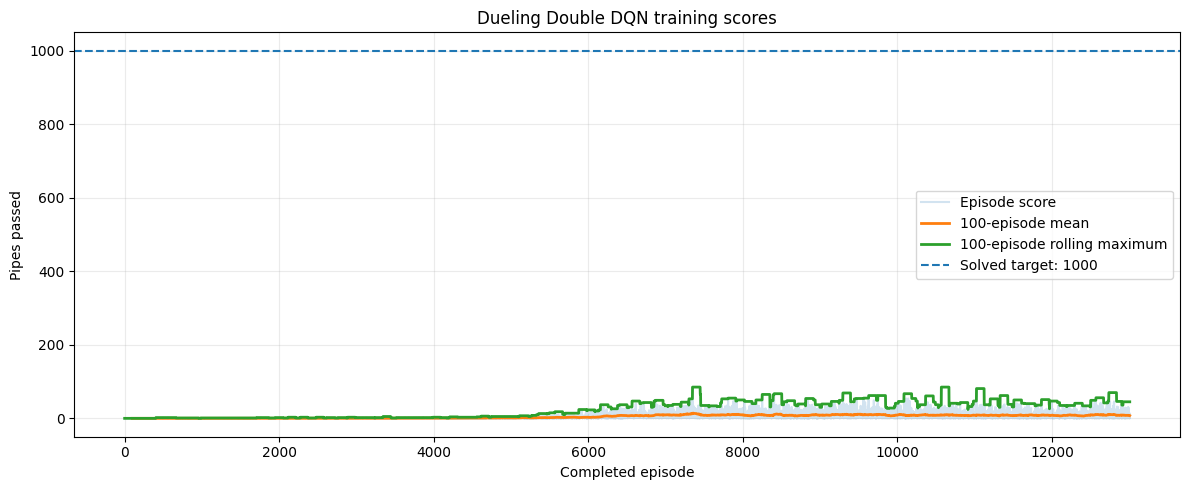

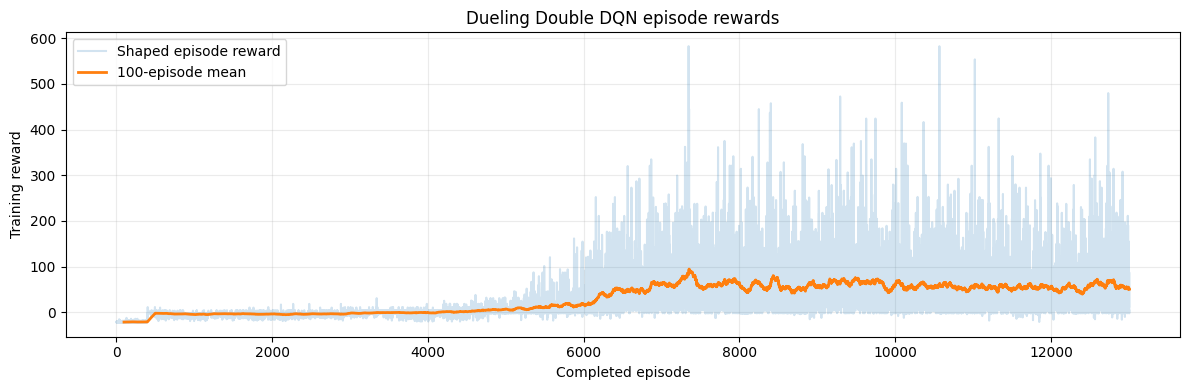

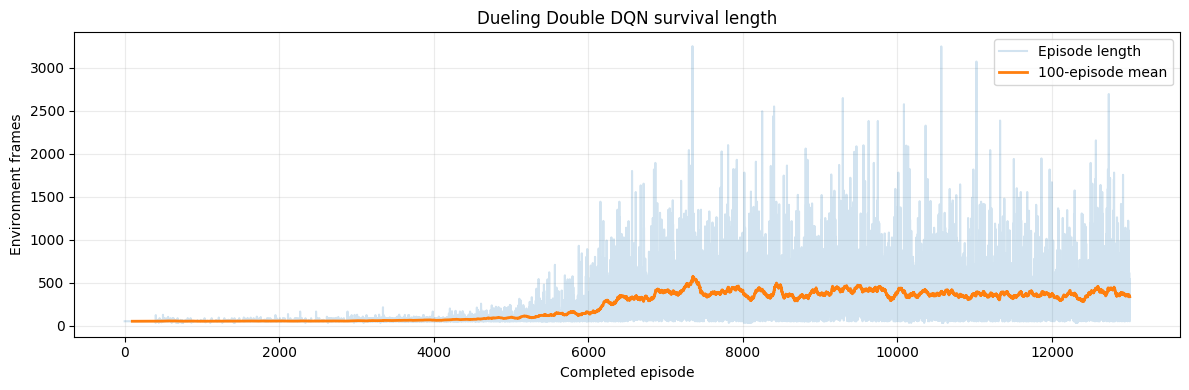

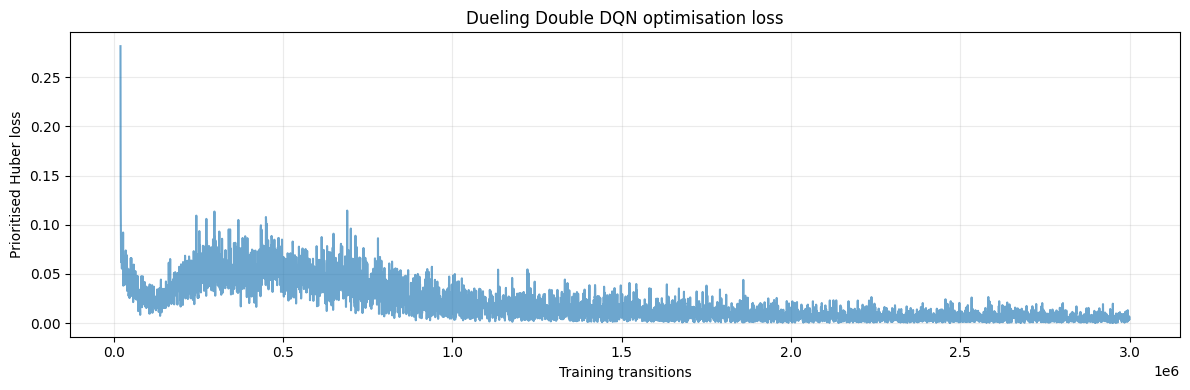

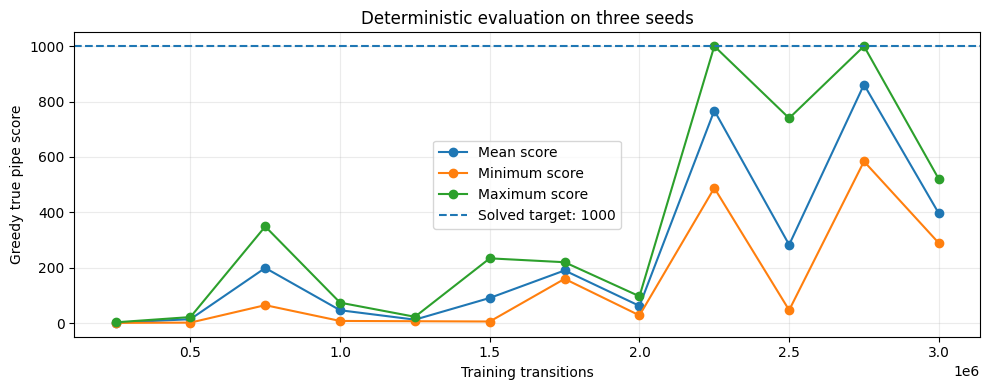

Best training score: 85
Final deterministic scores: [1000, 1000, 584]


In [8]:
scores = np.asarray(
    episode_scores,
    dtype=np.float32,
)

rewards = np.asarray(
    episode_rewards,
    dtype=np.float32,
)

lengths = np.asarray(
    episode_lengths,
    dtype=np.float32,
)

losses = np.asarray(
    loss_history,
    dtype=np.float32,
)

training_steps_array = np.asarray(
    training_step_history,
    dtype=np.int64,
)


def moving_average(
    values,
    window,
):
    if len(values) == 0:
        return (
            np.asarray([]),
            np.asarray([]),
        )

    window = min(
        int(window),
        len(values),
    )

    kernel = (
        np.ones(
            window,
            dtype=np.float32,
        )
        / window
    )

    smoothed = np.convolve(
        values,
        kernel,
        mode="valid",
    )

    x_values = np.arange(
        window - 1,
        len(values),
    )

    return x_values, smoothed


if scores.size > 0:
    x_values, score_mean = (
        moving_average(
            scores,
            100,
        )
    )

    rolling_max = np.asarray(
        [
            scores[
                max(0, index - 99):
                index + 1
            ].max()
            for index in range(
                scores.size
            )
        ],
        dtype=np.float32,
    )

    plt.figure(figsize=(12, 5))

    plt.plot(
        scores,
        alpha=0.20,
        label="Episode score",
    )

    plt.plot(
        x_values,
        score_mean,
        linewidth=2,
        label="100-episode mean",
    )

    plt.plot(
        rolling_max,
        linewidth=2,
        label=(
            "100-episode rolling maximum"
        ),
    )

    plt.axhline(
        TARGET_SCORE,
        linestyle="--",
        label=(
            f"Solved target: "
            f"{TARGET_SCORE}"
        ),
    )

    plt.xlabel("Completed episode")
    plt.ylabel("Pipes passed")

    plt.title(
        "Dueling Double DQN training scores"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        MODEL_DIR / "training_scores.png",
        dpi=150,
    )

    plt.show()
else:
    print(
        "No completed episodes were recorded."
    )


if rewards.size > 0:
    x_values, reward_mean = (
        moving_average(
            rewards,
            100,
        )
    )

    plt.figure(figsize=(12, 4))

    plt.plot(
        rewards,
        alpha=0.20,
        label="Shaped episode reward",
    )

    plt.plot(
        x_values,
        reward_mean,
        linewidth=2,
        label="100-episode mean",
    )

    plt.xlabel("Completed episode")
    plt.ylabel("Training reward")

    plt.title(
        "Dueling Double DQN episode rewards"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        MODEL_DIR / "episode_rewards.png",
        dpi=150,
    )

    plt.show()


if lengths.size > 0:
    x_values, length_mean = (
        moving_average(
            lengths,
            100,
        )
    )

    plt.figure(figsize=(12, 4))

    plt.plot(
        lengths,
        alpha=0.20,
        label="Episode length",
    )

    plt.plot(
        x_values,
        length_mean,
        linewidth=2,
        label="100-episode mean",
    )

    plt.xlabel("Completed episode")
    plt.ylabel("Environment frames")

    plt.title(
        "Dueling Double DQN survival length"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        MODEL_DIR / "episode_lengths.png",
        dpi=150,
    )

    plt.show()


if losses.size > 0:
    plot_stride = max(
        1,
        len(losses) // 5_000,
    )

    plt.figure(figsize=(12, 4))

    plt.plot(
        training_steps_array[
            ::plot_stride
        ],
        losses[::plot_stride],
        alpha=0.65,
    )

    plt.xlabel("Training transitions")
    plt.ylabel("Prioritised Huber loss")

    plt.title(
        "Dueling Double DQN optimisation loss"
    )

    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        MODEL_DIR / "training_loss.png",
        dpi=150,
    )

    plt.show()


if evaluation_history:
    evaluation_steps = [
        result["training_step"]
        for result in evaluation_history
    ]

    evaluation_means = [
        result["mean_score"]
        for result in evaluation_history
    ]

    evaluation_minimums = [
        result["minimum_score"]
        for result in evaluation_history
    ]

    evaluation_maximums = [
        result["maximum_score"]
        for result in evaluation_history
    ]

    plt.figure(figsize=(10, 4))

    plt.plot(
        evaluation_steps,
        evaluation_means,
        marker="o",
        label="Mean score",
    )

    plt.plot(
        evaluation_steps,
        evaluation_minimums,
        marker="o",
        label="Minimum score",
    )

    plt.plot(
        evaluation_steps,
        evaluation_maximums,
        marker="o",
        label="Maximum score",
    )

    plt.axhline(
        TARGET_SCORE,
        linestyle="--",
        label=(
            f"Solved target: "
            f"{TARGET_SCORE}"
        ),
    )

    plt.xlabel("Training transitions")
    plt.ylabel("Greedy true pipe score")

    plt.title(
        "Deterministic evaluation on three seeds"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        MODEL_DIR / "evaluation_scores.png",
        dpi=150,
    )

    plt.show()

print(
    f"Best training score: "
    f"{best_training_score}"
)

print(
    "Final deterministic scores: "
    f"{evaluation_result['scores']}"
)

## Visualizing model's performance

In [9]:
DEMO_SCORE_LIMIT = 10
DEMO_FRAME_SKIP = 3
DEMO_MAX_STEPS = 3_000
DEMO_FPS = 15
MAX_GIF_SIZE_MB = 20.0

demo_model, _ = load_dqn_checkpoint(
    selected_model_path,
    device=DEVICE,
)

demo_env = make_evaluation_env(
    target_score=DEMO_SCORE_LIMIT,
    render_mode="rgb_array",
)

observation, info = demo_env.reset(
    seed=2026
)

score = int(
    info.get("score", 0)
)

frames = []


def annotate_frame(
    frame,
    score_value,
    label="Dueling DDQN",
):
    image = PILImage.fromarray(frame)
    draw = ImageDraw.Draw(image)

    draw.rectangle(
        (6, 6, 156, 47),
        fill=(0, 0, 0),
    )

    draw.text(
        (12, 10),
        label,
        fill=(255, 255, 255),
    )

    draw.text(
        (12, 29),
        f"Score: {score_value}",
        fill=(255, 255, 255),
    )

    return np.asarray(image)


frames.append(
    annotate_frame(
        demo_env.render(),
        score,
    )
)

for step in range(
    1,
    DEMO_MAX_STEPS + 1,
):
    action = int(
        demo_model.choose_actions(
            np.expand_dims(
                observation,
                axis=0,
            ),
            epsilon=0.0,
        )[0]
    )

    (
        observation,
        _,
        terminated,
        truncated,
        info,
    ) = demo_env.step(action)

    score = int(
        info.get("score", score)
    )

    if (
        step % DEMO_FRAME_SKIP == 0
        or terminated
        or truncated
    ):
        frames.append(
            annotate_frame(
                demo_env.render(),
                score,
            )
        )

    if terminated or truncated:
        break

demo_env.close()

imageio.mimsave(
    GIF_PATH,
    frames,
    fps=DEMO_FPS,
    loop=0,
)

gif_size_mb = (
    GIF_PATH.stat().st_size
    / (1024 ** 2)
)

# Compress once if the GIF is too large.
if gif_size_mb > MAX_GIF_SIZE_MB:
    compressed_frames = []

    for frame in frames[::2]:
        image = PILImage.fromarray(frame)

        new_size = (
            max(
                1,
                int(image.width * 0.80),
            ),
            max(
                1,
                int(image.height * 0.80),
            ),
        )

        image = image.resize(
            new_size,
            PILImage.Resampling.LANCZOS,
        )

        compressed_frames.append(
            np.asarray(image)
        )

    imageio.mimsave(
        GIF_PATH,
        compressed_frames,
        fps=max(
            8,
            DEMO_FPS // 2,
        ),
        loop=0,
    )

    frames = compressed_frames

    gif_size_mb = (
        GIF_PATH.stat().st_size
        / (1024 ** 2)
    )

print(f"GIF score: {score}")
print(f"GIF frames: {len(frames)}")
print(f"GIF size: {gif_size_mb:.2f} MB")
print(f"Saved to: {GIF_PATH}")

GIF score: 10
GIF frames: 135
GIF size: 2.05 MB
Saved to: /kaggle/working/flappy_ddqn_first_10_scores.gif


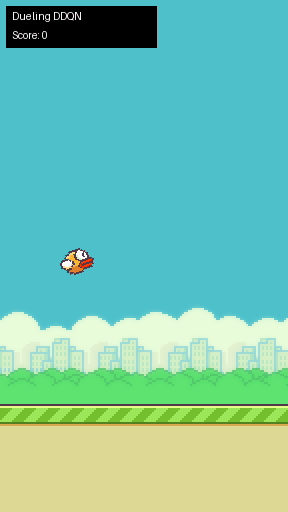

In [10]:
display(
    IPyImage(
        filename=str(GIF_PATH)
    )
)

## Export the score 1000 model

In [11]:
source_model_path = (
    BEST_MODEL_PATH
    if BEST_MODEL_PATH.exists()
    else FINAL_MODEL_PATH
)

shutil.copy2(
    source_model_path,
    EXPORT_MODEL_PATH,
)

metadata = {
    "algorithm": (
        "Dueling Double DQN with "
        "Prioritized Experience Replay"
    ),
    "observation_mode": (
        "12 normalized features; "
        "use_lidar=False"
    ),
    "target_score": TARGET_SCORE,
    "best_training_score": int(
        best_training_score
    ),
    "final_deterministic_evaluation": (
        evaluation_result
    ),
    "evaluation_history": (
        evaluation_history
    ),
    "seed": SEED,
    "pipe_gap": PIPE_GAP,
    "n_envs": N_ENVS,
    "total_training_steps": int(
        global_step
    ),
    "training_hours": float(
        training_hours
    ),
    "model_config": MODEL_CONFIG,
    "selected_source_model": str(
        source_model_path
    ),
}

metadata_path = (
    WORK_DIR
    / "flappy_ddqn_score_1000_metadata.json"
)

with metadata_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
    )

print(
    f"Exported model: "
    f"{EXPORT_MODEL_PATH}"
)

print(
    f"Exported metadata: "
    f"{metadata_path}"
)

print(
    f"Demonstration GIF: "
    f"{GIF_PATH}"
)

Exported model: /kaggle/working/flappy_ddqn_score_1000.pt
Exported metadata: /kaggle/working/flappy_ddqn_score_1000_metadata.json
Demonstration GIF: /kaggle/working/flappy_ddqn_first_10_scores.gif


## Running the saved score 1000 model

Loading model from: /kaggle/working/flappy_ddqn_score_1000.pt


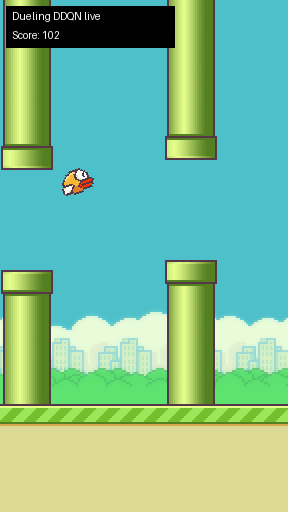

Live run ended: manual interruption
Score: 102
Reward: 479.1
Frames: 3,873
Solved 1000: False


In [12]:
LIVE_TARGET_SCORE = 1000
LIVE_MAX_STEPS = 60_000
LIVE_DISPLAY_EVERY = 3
LIVE_FPS = 30

# Set False to continue beyond 1000 until
# the bird crashes or you interrupt the cell.
STOP_AT_TARGET = True

live_model_path = EXPORT_MODEL_PATH

if not live_model_path.exists():
    matches = list(
        Path("/kaggle/input").rglob(
            "flappy_ddqn_score_1000.pt"
        )
    )

    if not matches:
        raise FileNotFoundError(
            "The exported DDQN model was not found. "
            "Run the export cell or attach the "
            "saved notebook output through Kaggle Input."
        )

    live_model_path = matches[0]

print(
    f"Loading model from: "
    f"{live_model_path}"
)

live_model, _ = load_dqn_checkpoint(
    live_model_path,
    device=DEVICE,
)

environment_score_limit = (
    LIVE_TARGET_SCORE
    if STOP_AT_TARGET
    else 1_000_000
)

live_env = make_evaluation_env(
    target_score=environment_score_limit,
    render_mode="rgb_array",
)

observation, info = live_env.reset(
    seed=777
)

live_score = int(
    info.get("score", 0)
)

live_reward = 0.0


def annotate_live_frame(
    frame,
    score_value,
):
    image = PILImage.fromarray(frame)
    draw = ImageDraw.Draw(image)

    draw.rectangle(
        (6, 6, 174, 47),
        fill=(0, 0, 0),
    )

    draw.text(
        (12, 10),
        "Dueling DDQN live",
        fill=(255, 255, 255),
    )

    draw.text(
        (12, 29),
        f"Score: {score_value}",
        fill=(255, 255, 255),
    )

    return image


display_handle = display(
    annotate_live_frame(
        live_env.render(),
        live_score,
    ),
    display_id=True,
)

run_ended_by = (
    "maximum step safety limit"
)

try:
    for live_step in range(
        1,
        LIVE_MAX_STEPS + 1,
    ):
        action = int(
            live_model.choose_actions(
                np.expand_dims(
                    observation,
                    axis=0,
                ),
                epsilon=0.0,
            )[0]
        )

        (
            observation,
            reward,
            terminated,
            truncated,
            info,
        ) = live_env.step(action)

        live_reward += float(reward)

        live_score = int(
            info.get(
                "score",
                live_score,
            )
        )

        if (
            live_step
            % LIVE_DISPLAY_EVERY
            == 0
            or terminated
            or truncated
        ):
            display_handle.update(
                annotate_live_frame(
                    live_env.render(),
                    live_score,
                )
            )

            time.sleep(
                LIVE_DISPLAY_EVERY
                / LIVE_FPS
            )

        if terminated:
            run_ended_by = (
                "bird crashed"
            )
            break

        if truncated:
            run_ended_by = (
                "target score reached"
                if live_score
                >= environment_score_limit
                else "environment truncated"
            )
            break

except KeyboardInterrupt:
    run_ended_by = (
        "manual interruption"
    )

finally:
    live_env.close()

print(
    f"Live run ended: {run_ended_by}\n"
    f"Score: {live_score}\n"
    f"Reward: {live_reward:.1f}\n"
    f"Frames: {live_step:,}\n"
    f"Solved 1000: "
    f"{live_score >= LIVE_TARGET_SCORE}"
)